# Customer Support Data Analysis

## 1. Project Objective

Analyze customer support ticket data to identify trends and provide
actionable insights for improving customer service.

### Business Questions
- What is the average resolution time by priority level?
- Which category has the highest customer satisfaction?
- What percentage of tickets are resolved within 24 hours?
- How does customer satisfaction correlate with resolution time?

### Project Duration
1 week

### Tools and Techniques
- Python and Pandas
- Exploratory Data Analysis (EDA)
- Descriptive statistics and correlation analysis
- Matplotlib and Seaborn for visualization
- Tableau for dashboard development

## Analytical Approach

The analysis evaluates customer support performance by examining ticket volume, resolution efficiency, and customer satisfaction. Exploratory Data Analysis (EDA), descriptive statistics, group comparisons, and correlation analysis will be used to identify trends, patterns, and performance gaps.

Bar charts, line charts, and scatter plots will visualize ticket distribution, resolution time trends, satisfaction across categories, and relationships between resolution time and customer satisfaction. The findings will support actionable recommendations and guide the development of an interactive Tableau dashboard.

## 1. Data Loading and Initial Inspection

Load the customer support dataset and examine its structure, dimensions,
column names, data types, and summary statistics.

In [57]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

df = pd.read_csv(r"C:\Users\Krish\OneDrive\Desktop\KrishnaWorkspace\my-portfolio\Customer Support Data Analysis\02-Raw and cleaned Data\Customer_Support_Data_Analysis_sample_data_Cleaned Data.csv")

print("Dataset dimensions:", df.shape)
display(df.head())
df.info()
display(df.describe(include="all"))

Dataset dimensions: (25, 9)


,ticket_id,date,category,priority,status,resolution_time,customer_satisfaction,customer_email,agent_name
0,1001,1/15/2024,Login Issues,High,Closed,2.5,4.0,customer1@email.com,Sarah Johnson
1,1002,1/15/2024,Billing,Medium,Closed,4.0,3.0,customer2@email.com,Mike Chen
2,1003,1/16/2024,Technical,Low,Open,NaN,NaN,NaN,Tom Wilson
3,1004,1/16/2024,Login Issues,High,Closed,1.5,5.0,customer4@email.com,Sarah Johnson
4,1005,1/17/2024,Billing,Medium,Closed,6.0,2.0,customer5@email.com,Lisa Davis


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 25 entries, 0 to 24
Data columns (total 9 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   ticket_id              25 non-null     int64  
 1   date                   25 non-null     object 
 2   category               25 non-null     object 
 3   priority               25 non-null     object 
 4   status                 25 non-null     object 
 5   resolution_time        21 non-null     float64
 6   customer_satisfaction  21 non-null     float64
 7   customer_email         22 non-null     object 
 8   agent_name             25 non-null     object 
dtypes: float64(2), int64(1), object(6)
memory usage: 1.9+ KB


,ticket_id,date,category,priority,status,resolution_time,customer_satisfaction,customer_email,agent_name
count,25.000000,25,25,25,25,21.000000,21.000000,22,25
unique,NaN,13,4,3,3,NaN,NaN,22,5
top,NaN,1/15/2024,Login Issues,Medium,Closed,NaN,NaN,customer1@email.com,Sarah Johnson
freq,NaN,2,8,10,21,NaN,NaN,1,7
mean,1013.000000,NaN,NaN,NaN,NaN,4.904762,3.571429,NaN,NaN
std,7.359801,NaN,NaN,NaN,NaN,3.448257,1.075706,NaN,NaN
min,1001.000000,NaN,NaN,NaN,NaN,1.000000,1.000000,NaN,NaN
25%,1007.000000,NaN,NaN,NaN,NaN,2.500000,3.000000,NaN,NaN
50%,1013.000000,NaN,NaN,NaN,NaN,4.000000,4.000000,NaN,NaN
75%,1019.000000,NaN,NaN,NaN,NaN,6.000000,4.000000,NaN,NaN


## 2. Data Cleaning

Assess missing values, duplicate records, date consistency, data types,
and invalid values before performing analysis.

Missing values will be handled according to their business meaning.

In [58]:
# Missing Value and Duplicate Values
df = df.copy()

# Standardize column names
df.columns = df.columns.str.strip().str.lower()

# Check missing values
missing_summary = pd.DataFrame({
    "Missing_Count": df.isnull().sum(),
    "Missing_Percentage": (df.isnull().mean() * 100).round(2)
})

display(missing_summary)

# Check duplicates
print("Exact duplicate rows:", df.duplicated().sum())
print("Duplicate ticket IDs:",
      df["ticket_id"].duplicated().sum())

,Missing_Count,Missing_Percentage
ticket_id,0,0.0
date,0,0.0
category,0,0.0
priority,0,0.0
status,0,0.0
resolution_time,4,16.0
customer_satisfaction,4,16.0
customer_email,3,12.0
agent_name,0,0.0


Exact duplicate rows: 0
Duplicate ticket IDs: 0


In [59]:
#Date Format
df["date"] = pd.to_datetime(
    df["date"],
    errors="coerce"
)

df["date"].head()

0   2024-01-15
1   2024-01-15
2   2024-01-16
3   2024-01-16
4   2024-01-17
Name: date, dtype: datetime64[ns]

In [60]:
#Convert Numeric column
df["resolution_time"] = pd.to_numeric(
    df["resolution_time"],
    errors="coerce"
)

df["customer_satisfaction"] = pd.to_numeric(
    df["customer_satisfaction"],
    errors="coerce"
)

In [61]:
#Standardized Text
text_columns = ["category", "priority", "status"]

for col in text_columns:
    df[col] = df[col].apply(
        lambda x: x.strip().title()
        if isinstance(x, str) else x
    )

In [62]:
# Invalid satisfaction scores
invalid_satisfaction = df[
    df["customer_satisfaction"].notna() &
    ~df["customer_satisfaction"].between(1, 5)
]

# Negative resolution times
invalid_resolution = df[
    df["resolution_time"] < 0
]

display(invalid_satisfaction)
display(invalid_resolution)

,ticket_id,date,category,priority,status,resolution_time,customer_satisfaction,customer_email,agent_name


,ticket_id,date,category,priority,status,resolution_time,customer_satisfaction,customer_email,agent_name


In [63]:
df.to_csv(
    "customer_support_cleaned.csv",
    index=False
)

##Perform exploratory data analysis (EDA)

In [64]:
###Number of tickets by category
display(df["category"].value_counts())

category
Login Issues       8
Billing            7
Technical          7
Feature Request    3
Name: count, dtype: int64

In [65]:
###Average resolution time by priority
closed = df[
    (df["status"] == "Closed") &
    (df["resolution_time"].notna()) &
    (df["resolution_time"] >= 0)
]

display(
    closed.groupby("priority")["resolution_time"]
    .mean()
    .sort_values()
)

priority
High      3.833333
Medium    3.944444
Low       7.416667
Name: resolution_time, dtype: float64

In [66]:
###Category with the highest customer satisfaction
display(
    df.groupby("category")["customer_satisfaction"]
    .mean()
    .sort_values(ascending=False)
)

category
Login Issues       4.428571
Technical          4.000000
Feature Request    3.500000
Billing            2.428571
Name: customer_satisfaction, dtype: float64

In [67]:

###Percentage of tickets resolved within 24 hours
eligible = df[
    (df["status"] == "Closed") &
    (df["resolution_time"].notna()) &
    (df["resolution_time"] >= 0)
]

within_24 = (
    eligible["resolution_time"] <= 24
).sum()

percentage = (
    within_24 / len(eligible) * 100
    if len(eligible) > 0 else np.nan
)

print(f"Resolved within 24 hours: {percentage:.2f}%")

Resolved within 24 hours: 100.00%


In [68]:
###Correlation between resolution time and satisfaction
analysis_df = df[
    (df["status"] == "Closed") &
    df["resolution_time"].notna() &
    df["customer_satisfaction"].notna() &
    (df["resolution_time"] >= 0) &
    (df["customer_satisfaction"].between(1, 5))
]

correlation = analysis_df[
    ["resolution_time", "customer_satisfaction"]
].corr().iloc[0, 1]

print("Correlation:", correlation)

Correlation: -0.510299009098604


## visualizations in Python

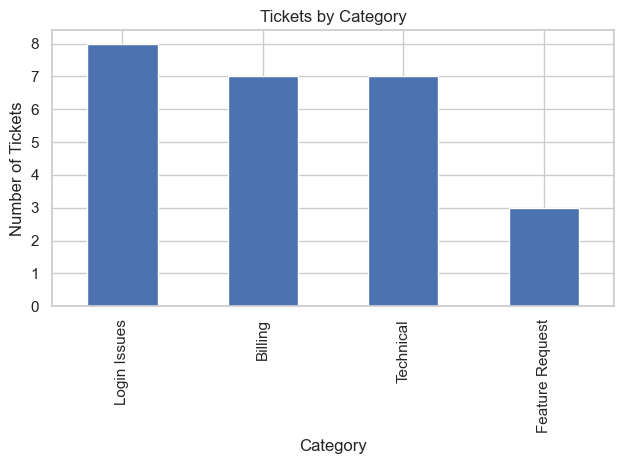

In [69]:
###Tickets by category
df["category"].value_counts().plot(
    kind="bar",
    title="Tickets by Category",
    xlabel="Category",
    ylabel="Number of Tickets"
)

plt.tight_layout()
plt.show()

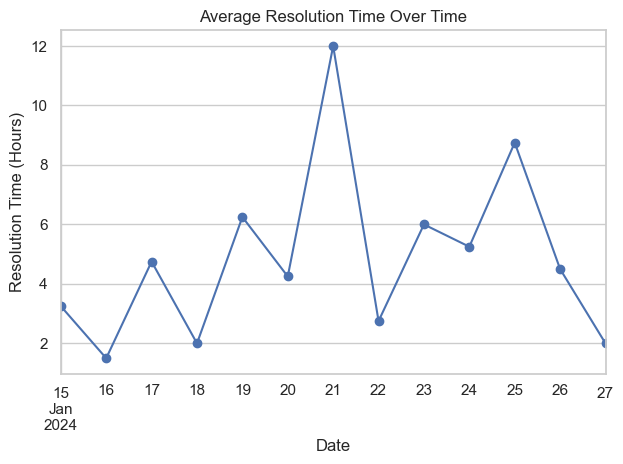

In [70]:

###Resolution time trends
daily_resolution = (
    closed.groupby("date")["resolution_time"]
    .mean()
)

daily_resolution.plot(
    kind="line",
    marker="o",
    title="Average Resolution Time Over Time",
    xlabel="Date",
    ylabel="Resolution Time (Hours)"
)

plt.tight_layout()
plt.show()

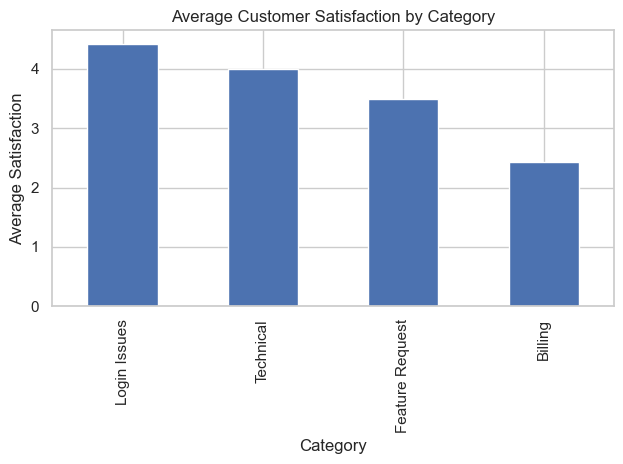

In [71]:
###Satisfaction by category
satisfaction = (
    df.groupby("category")["customer_satisfaction"]
    .mean()
    .sort_values(ascending=False)
)

satisfaction.plot(
    kind="bar",
    title="Average Customer Satisfaction by Category",
    xlabel="Category",
    ylabel="Average Satisfaction"
)

plt.tight_layout()
plt.show()

## 14. Key Findings and Recommendations

### Ticket distribution: The dataset contains 25 tickets across four categories. Login Issues accounts for 8 tickets (32%), while Billing and Technical each account for 7 tickets (28%). Feature Requests account for 3 tickets (12%).
### Ticket status: 21 tickets (84%) are Closed, 3 (12%) are Open, and 1 (4%) is In Progress.
### Resolution efficiency: Average resolution time is 4.90 hours, with a median of 4 hours. Average resolution times by priority are 3.83 hours for High, 3.94 hours for Medium, and 7.42 hours for Low.
### Customer satisfaction: Average satisfaction is 3.57 out of 5 across 21 recorded ratings. Login Issues has the highest category average at 4.43, while Billing has the lowest at 2.43.
### 24-hour resolution: All 21 tickets with recorded resolution times were resolved within 24 hours (100%). The four unresolved tickets are excluded from this calculation.
### Correlation: The Pearson correlation between resolution time and customer satisfaction is -0.510, indicating a moderate negative association in this sample.
### Recommendations
1. Investigate recurring Login Issues and consider improving self-service troubleshooting resources.
2. Review Billing tickets and customer feedback to identify causes of low satisfaction.
3. Investigate why Low-priority tickets have longer average resolution times and review workload allocation and ticket complexity.
4. Continue monitoring resolution performance and unresolved ticket age. 5. 5. Collect additional data across multiple months to assess long-term trends and determine whether recommended changes improve outcomes.

